# **Installing Required  Libarey**

In [ ]:
!pip install catboost
!pip install shap
!pip install lime
!pip install imbalanced-learn # imbalanced-learn is the name of the library on PyPi (pip)
!pip install xgboost

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **Importing Required Library**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from imblearn.over_sampling import SMOTE
from sklearn.feature_selection import chi2, SelectKBest
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score ,confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from catboost import CatBoostClassifier
import xgboost as xgb
import numpy as np
from sklearn.model_selection import cross_val_score, cross_val_predict, KFold
import os
import time
from seaborn import heatmap
import seaborn as sns
from sklearn.ensemble import VotingClassifier
import shap
from lime import lime_tabular

import catboost
from catboost import *
import shap
shap.initjs()

# **Importing Dataset**

In [ ]:

dt=pd.read_csv("/content/drive/MyDrive/Colab Files/Survey on Procrastination and Academic Performance  (Responses) - Form Responses.csv")
dt.drop(["Timestamp"],axis=1,inplace=True)

dt

,study_year,socio-economic_background,assignment_delay_frequency,procrastination_reasons,assignment_submission_timing,last_minute_exam_preparation,effect_of_procrastination_on_grades,procrastination_and_grade_outcome,stress_due_to_procrastination,study_hours_per_week,cgpa,use_of_time_management,procrastination_management_training,procrastination_recovery_strategies,hours_spent_on_mobile_non_academic,study_session_distractions
0,Fourth Year,Middle,Always,"Lack of interest, Health issues",Never,Yes,Significantly,Yes,Significantly,0-5 hours,2.50 - 2.99,Always,Yes,Yes,1-2 hours,Sometimes
1,Third Year,Middle,Often,"Procrastination due to lack of resources, Heal...",Occasionally,Yes,Moderately,Yes,Not at all,0-5 hours,3.00 - 3.49,Never,Yes,No,More than 4 hours,Sometimes
2,Second Year,Lower-middle,Occasionally,"Distractions (e.g., social media), Health issues",Sometimes,Yes,Not at all,No,Moderately,6-10 hours,3.00 - 3.49,Never,No,Yes,3-4 hours,Occasionally
3,Fourth Year,High,Always,"Procrastination due to lack of resources, Heal...",Sometimes,Yes,Not at all,Yes,Significantly,0-5 hours,Below 2.50,Never,No,No,More than 4 hours,Often
4,Third Year,Upper-middle,Sometimes,Lack of interest,Never,No,Significantly,No,Slightly,6-10 hours,3.50 - 3.74,Sometimes,Yes,No,More than 4 hours,Always
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
450,Second Year,Low,Never,"Distractions (e.g., social media), Procrastina...",Often,Yes,Moderately,No,Significantly,16+ hours,3.50 - 3.74,Never,No,Yes,1-2 hours,Always
451,Third Year,Lower-middle,Always,"Unclear instructions from professors, Personal...",Sometimes,No,Significantly,Yes,Slightly,0-5 hours,Below 2.50,Never,Yes,No,More than 4 hours,Occasionally
452,Second Year,High,Often,"Stress and anxiety, Procrastination due to lac...",Sometimes,No,Significantly,Yes,Significantly,0-5 hours,3.00 - 3.49,Often,Yes,No,3-4 hours,Always
453,Third Year,Low,Sometimes,"Procrastination due to lack of resources, Uncl...",Occasionally,Yes,Not at all,No,Significantly,0-5 hours,3.50 - 3.74,Always,Yes,No,1-2 hours,Often


# **Pre-Processing**

In [ ]:
dt.isnull().sum()

,0
study_year,0
socio-economic_background,6
assignment_delay_frequency,0
procrastination_reasons,0
assignment_submission_timing,0
last_minute_exam_preparation,0
effect_of_procrastination_on_grades,0
procrastination_and_grade_outcome,0
stress_due_to_procrastination,0
study_hours_per_week,0


In [ ]:

dt.dropna(inplace=True)
dt

,study_year,socio-economic_background,assignment_delay_frequency,procrastination_reasons,assignment_submission_timing,last_minute_exam_preparation,effect_of_procrastination_on_grades,procrastination_and_grade_outcome,stress_due_to_procrastination,study_hours_per_week,cgpa,use_of_time_management,procrastination_management_training,procrastination_recovery_strategies,hours_spent_on_mobile_non_academic,study_session_distractions
0,Fourth Year,Middle,Always,"Lack of interest, Health issues",Never,Yes,Significantly,Yes,Significantly,0-5 hours,2.50 - 2.99,Always,Yes,Yes,1-2 hours,Sometimes
1,Third Year,Middle,Often,"Procrastination due to lack of resources, Heal...",Occasionally,Yes,Moderately,Yes,Not at all,0-5 hours,3.00 - 3.49,Never,Yes,No,More than 4 hours,Sometimes
2,Second Year,Lower-middle,Occasionally,"Distractions (e.g., social media), Health issues",Sometimes,Yes,Not at all,No,Moderately,6-10 hours,3.00 - 3.49,Never,No,Yes,3-4 hours,Occasionally
3,Fourth Year,High,Always,"Procrastination due to lack of resources, Heal...",Sometimes,Yes,Not at all,Yes,Significantly,0-5 hours,Below 2.50,Never,No,No,More than 4 hours,Often
4,Third Year,Upper-middle,Sometimes,Lack of interest,Never,No,Significantly,No,Slightly,6-10 hours,3.50 - 3.74,Sometimes,Yes,No,More than 4 hours,Always
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
450,Second Year,Low,Never,"Distractions (e.g., social media), Procrastina...",Often,Yes,Moderately,No,Significantly,16+ hours,3.50 - 3.74,Never,No,Yes,1-2 hours,Always
451,Third Year,Lower-middle,Always,"Unclear instructions from professors, Personal...",Sometimes,No,Significantly,Yes,Slightly,0-5 hours,Below 2.50,Never,Yes,No,More than 4 hours,Occasionally
452,Second Year,High,Often,"Stress and anxiety, Procrastination due to lac...",Sometimes,No,Significantly,Yes,Significantly,0-5 hours,3.00 - 3.49,Often,Yes,No,3-4 hours,Always
453,Third Year,Low,Sometimes,"Procrastination due to lack of resources, Uncl...",Occasionally,Yes,Not at all,No,Significantly,0-5 hours,3.50 - 3.74,Always,Yes,No,1-2 hours,Often


In [ ]:
dt.isnull().sum()

,0
study_year,0
socio-economic_background,0
assignment_delay_frequency,0
procrastination_reasons,0
assignment_submission_timing,0
last_minute_exam_preparation,0
effect_of_procrastination_on_grades,0
procrastination_and_grade_outcome,0
stress_due_to_procrastination,0
study_hours_per_week,0


# **Balance imbalance check**

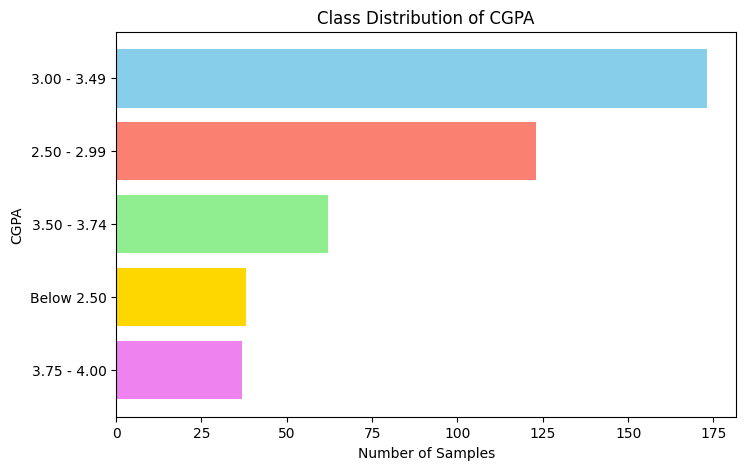

<Figure size 640x480 with 0 Axes>

In [ ]:

color_mapping = {
    'Below 2.50': 'gold',
    '2.50 - 2.99': 'salmon',
    '3.00 - 3.49': 'skyblue',
    '3.50 - 3.74': 'lightgreen',
    '3.75 - 4.00': 'violet'
}


plt.figure(figsize=(8, 5))
class_distribution = dt['cgpa'].value_counts()
plt.barh(
    class_distribution.index,
    class_distribution.values,
    color=[color_mapping[label] for label in class_distribution.index]
)
plt.title('Class Distribution of CGPA')
plt.xlabel('Number of Samples')
plt.ylabel('CGPA')
plt.gca().invert_yaxis()
plt.show()
plt.savefig('class_distribution.png', bbox_inches='tight', pad_inches=0.1)


In [ ]:
feature_names=dt.columns
feature_names

Index(['study_year', 'socio-economic_background', 'assignment_delay_frequency',
       'procrastination_reasons', 'assignment_submission_timing',
       'last_minute_exam_preparation', 'effect_of_procrastination_on_grades',
       'procrastination_and_grade_outcome', 'stress_due_to_procrastination',
       'study_hours_per_week', 'cgpa', 'use_of_time_management',
       'procrastination_management_training',
       'procrastination_recovery_strategies',
       'hours_spent_on_mobile_non_academic', 'study_session_distractions'],
      dtype='object')

# **Lebel Encoding**

In [ ]:

le = LabelEncoder()

for column in dt.columns:
    if dt[column].dtype == 'object' or dt[column].dtype.name == 'category':
        dt[column] = le.fit_transform(dt[column])
dt


,study_year,socio-economic_background,assignment_delay_frequency,procrastination_reasons,assignment_submission_timing,last_minute_exam_preparation,effect_of_procrastination_on_grades,procrastination_and_grade_outcome,stress_due_to_procrastination,study_hours_per_week,cgpa,use_of_time_management,procrastination_management_training,procrastination_recovery_strategies,hours_spent_on_mobile_non_academic,study_session_distractions
0,1,3,0,40,1,1,2,1,2,0,0,0,1,1,0,4
1,5,3,3,90,2,1,0,1,1,0,1,1,1,0,2,4
2,4,2,2,1,4,1,1,0,0,3,1,1,0,1,1,2
3,1,0,0,90,4,1,1,1,2,0,4,1,0,0,2,3
4,5,4,4,30,1,0,2,0,3,3,2,4,1,0,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
450,4,1,1,12,3,1,0,0,2,2,2,1,0,1,0,0
451,5,2,0,116,4,0,2,1,3,0,4,1,1,0,2,2
452,4,0,3,106,4,0,2,1,2,0,1,3,1,0,1,0
453,5,1,4,98,2,1,1,0,2,0,2,0,1,0,0,3


# **Data Balancing Using SMOTE**

In [ ]:


X = dt.drop('cgpa', axis=1)
y = dt['cgpa']

smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

resampled_data = pd.DataFrame(X_resampled, columns=X.columns)
resampled_data['cgpa'] = y_resampled

dt = resampled_data

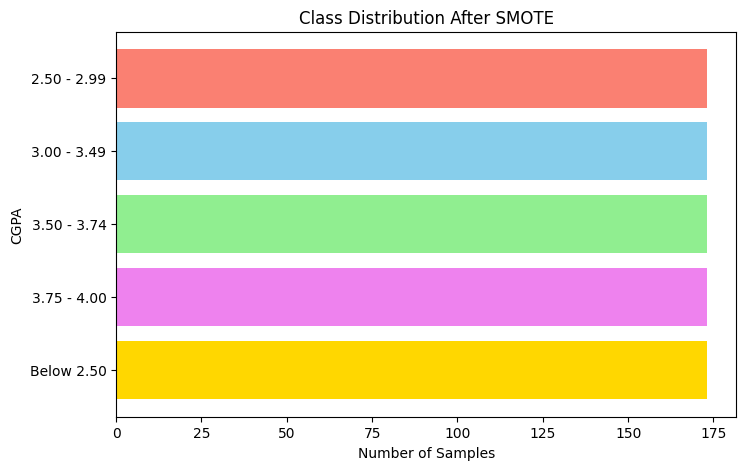

<Figure size 640x480 with 0 Axes>

In [ ]:
resampled_class_distribution = y_resampled.value_counts()


color_mapping = {
    4: 'gold',
    0: 'salmon',
    1: 'skyblue',
    2: 'lightgreen',
    3: 'violet'
}


class_names = {
    0: "2.50 - 2.99",
    1: "3.00 - 3.49",
    2: "3.50 - 3.74",
    3: "3.75 - 4.00",
    4: "Below 2.50"
}


plt.figure(figsize=(8, 5))
plt.barh(
    resampled_class_distribution.index,
    resampled_class_distribution.values,
    color=[color_mapping[label] for label in resampled_class_distribution.index]
)
plt.title('Class Distribution After SMOTE')
plt.xlabel('Number of Samples')
plt.ylabel('CGPA')
plt.yticks(
    ticks=resampled_class_distribution.index,
    labels=[class_names[idx] for idx in resampled_class_distribution.index],
    rotation=0
)
plt.gca().invert_yaxis()
plt.show()
plt.savefig('class_distribution AfterSMOTE.png', bbox_inches='tight', pad_inches=0.1)


# **Feature Check**

In [ ]:
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler

# Example Data
# Separate features and target variable
X = dt.drop('cgpa', axis=1)
y = dt['cgpa']

# Ensure features are non-negative for chi2 (use MinMaxScaler)
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# Test different values of k, ensure k is less than or equal to the number of features
max_features = X_scaled.shape[1]

for k in range(1, min(15, max_features + 1)):  # Ensure k is within the feature count
    selector = SelectKBest(score_func=chi2, k=k)
    X_selected = selector.fit_transform(X_scaled, y)

    # Evaluate with cross-validation
    model = RandomForestClassifier(random_state=42)
    scores = cross_val_score(model, X_selected, y, cv=5)
    print(f"k={k}, Mean Accuracy: {scores.mean():.4f}")



k=1, Mean Accuracy: 0.3988
k=2, Mean Accuracy: 0.4740
k=3, Mean Accuracy: 0.7376
k=4, Mean Accuracy: 0.7237
k=5, Mean Accuracy: 0.7075
k=6, Mean Accuracy: 0.6798
k=7, Mean Accuracy: 0.7006
k=8, Mean Accuracy: 0.7249
k=9, Mean Accuracy: 0.7410
k=10, Mean Accuracy: 0.7642
k=11, Mean Accuracy: 0.7618
k=12, Mean Accuracy: 0.7665
k=13, Mean Accuracy: 0.7723
k=14, Mean Accuracy: 0.8012


In [ ]:
from sklearn.feature_selection import chi2, SelectKBest
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

# Example: Your dataset (replace `dt` with your actual DataFrame)
# dt = pd.read_csv('your_dataset.csv')

# Separate features and target variable
X = dt.drop('cgpa', axis=1)
y = dt['cgpa']



# Perform Chi-Square test
chi2_scores, p_values = chi2(X, y)

# Create a DataFrame to display feature scores
feature_scores = pd.DataFrame({
    'Feature': dt.drop('cgpa', axis=1).columns,
    'Chi2 Score': chi2_scores,
    'P-value': p_values
}).sort_values(by='Chi2 Score', ascending=False)

print("Chi2 Scores for Features:")
print(feature_scores)

# Select top k features
k = 14  # Adjust 'k' based on your needs
top_features = SelectKBest(chi2, k=k).fit(X, y)

# Display top selected features
selected_features = dt.drop('cgpa', axis=1).columns[top_features.get_support()]
print("\nTop Features Selected:")
print(selected_features)

# Create a new DataFrame with the top selected features and the target variable
top_features_list = selected_features.to_list()  # Convert selected features to a list
dt = dt[top_features_list + ['cgpa']]  # Replace original DataFrame

# Display the new DataFrame
print("Updated DataFrame with Top Features:")
dt



Chi2 Scores for Features:
                                Feature  Chi2 Score        P-value
2            assignment_delay_frequency  626.607071  2.699930e-134
9                  study_hours_per_week  495.267477  7.072840e-106
3               procrastination_reasons  466.432065   1.216692e-99
7     procrastination_and_grade_outcome  355.654028   1.054732e-75
8         stress_due_to_procrastination   46.194842   2.243303e-09
13   hours_spent_on_mobile_non_academic   43.458221   8.312844e-09
1             socio-economic_background   28.173077   1.150492e-05
14           study_session_distractions   28.148198   1.163933e-05
10               use_of_time_management   26.714582   2.270256e-05
0                            study_year   23.936242   8.225991e-05
6   effect_of_procrastination_on_grades   21.055077   3.088052e-04
12  procrastination_recovery_strategies   19.551601   6.121717e-04
5          last_minute_exam_preparation   13.867816   7.729104e-03
4          assignment_submission_tim

,study_year,socio-economic_background,assignment_delay_frequency,procrastination_reasons,assignment_submission_timing,last_minute_exam_preparation,effect_of_procrastination_on_grades,procrastination_and_grade_outcome,stress_due_to_procrastination,study_hours_per_week,use_of_time_management,procrastination_recovery_strategies,hours_spent_on_mobile_non_academic,study_session_distractions,cgpa
0,1,3,0,40,1,1,2,1,2,0,0,1,0,4,0
1,5,3,3,90,2,1,0,1,1,0,1,0,2,4,1
2,4,2,2,1,4,1,1,0,0,3,1,1,1,2,1
3,1,0,0,90,4,1,1,1,2,0,1,0,2,3,4
4,5,4,4,30,1,0,2,0,3,3,4,0,2,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
860,4,3,0,38,2,0,0,1,0,0,3,0,0,2,4
861,4,2,0,80,1,0,0,1,0,0,0,0,0,4,4
862,0,0,0,91,2,0,1,1,1,0,1,0,1,3,4
863,3,3,0,86,4,0,1,1,2,0,3,0,1,1,4


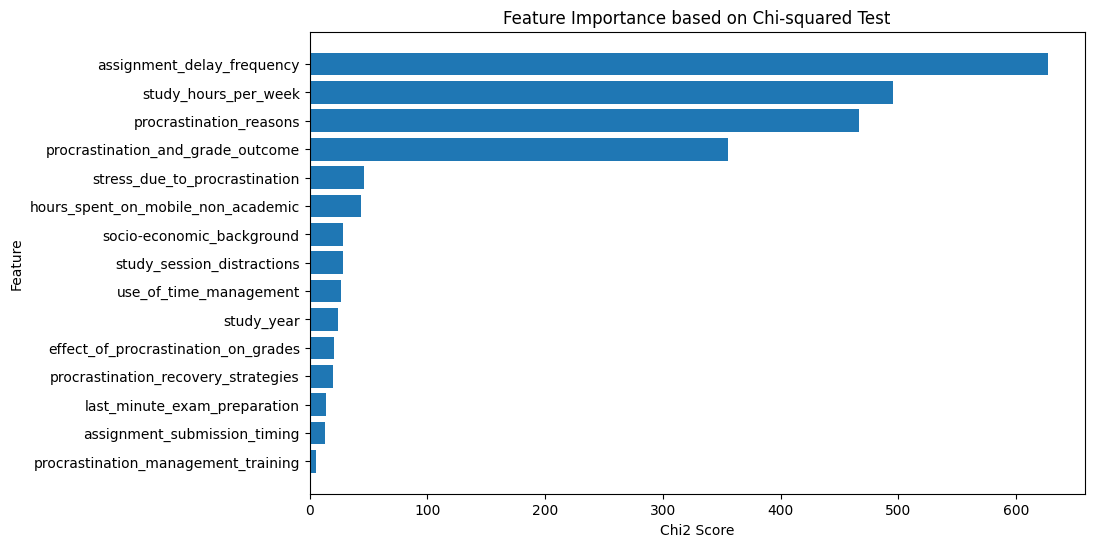

<Figure size 640x480 with 0 Axes>

In [ ]:

plt.figure(figsize=(10, 6))
plt.barh(feature_scores['Feature'], feature_scores['Chi2 Score'])
plt.xlabel('Chi2 Score')
plt.ylabel('Feature')
plt.title('Feature Importance based on Chi-squared Test')
plt.gca().invert_yaxis()
plt.show()
plt.savefig('Feature Importance.png', bbox_inches='tight', pad_inches=0.1)

# **Model Training**

In [ ]:



X = dt.drop('cgpa', axis=1)
y = dt['cgpa']
cat_features = list(range(0, X.shape[1]))
classification_models = {
    "Logistic Regression": LogisticRegression(max_iter=1500),
    "Decision Tree": DecisionTreeClassifier(),
    "KNN": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(),
    #"SVM": SVC(probability=True),
    "Gradient Boosting": GradientBoostingClassifier(),
    "CatBoost": CatBoostClassifier(loss_function = 'MultiClass',cat_features=cat_features, verbose=False),
    "XGBoost": xgb.XGBClassifier(eval_metric='mlogloss')
}

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

classification_reports = {}
classification_model={}

print("\n=== Classification Models ===")
for model_name, model in classification_models.items():
    print(f"\nTraining {model_name}...")
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    classification_model[model_name]=model

    print("\nClassification Report:")
    report = classification_report(y_test, y_pred, zero_division=0)
    print(report)

    classification_reports[model_name] = classification_report(y_test, y_pred, output_dict=True, zero_division=0)





=== Classification Models ===

Training Logistic Regression...


/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.64      0.67        39
           1       0.43      0.38      0.41        26
           2       0.79      0.70      0.74        33
           3       0.87      0.97      0.92        34
           4       0.87      1.00      0.93        41

    accuracy                           0.76       173
   macro avg       0.73      0.74      0.73       173
weighted avg       0.75      0.76      0.75       173


Training Decision Tree...

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.67      0.68        39
           1       0.43      0.50      0.46        26
           2       0.74      0.79      0.76        33
           3       0.97      0.91      0.94        34
           4       0.95      0.90      0.93        41

    accuracy                           0.77       173
   macro avg       0.76      0.75      0.76       173
we

In [ ]:


# Define VotingClassifier using pre-trained models
voting_clf = VotingClassifier(
    estimators=[
        ('Logistic Regression', classification_models["Logistic Regression"]),
        ('Decision Tree', classification_models["Decision Tree"]),
        ('KNN', classification_models["KNN"]),
        ('Naive Bayes', classification_models["Naive Bayes"]),
        ('Random Forest', classification_models["Random Forest"]),
       # ('SVM', classification_models["SVM"]),
        ('Gradient Boosting', classification_models["Gradient Boosting"]),
        ('CatBoost', classification_models["CatBoost"]),
        ('XGBoost', classification_models["XGBoost"])
    ],
    voting='soft',  # Use probabilities for aggregation
    n_jobs=-1  # Use all available cores
)

# Train the VotingClassifier
print("\nTraining Voting Classifier...")
voting_clf.fit(X_train, y_train)

# Predict on the test set
y_pred = voting_clf.predict(X_test)

# Evaluate the VotingClassifier
accuracy = accuracy_score(y_test, y_pred)
print(f"\nVoting Classifier Accuracy: {accuracy:.4f}")
print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Store the trained VotingClassifier in the dictionary
classification_model["Voting Classifier"] = voting_clf
classification_reports["Voting Classifier"] = classification_report(y_test, y_pred, output_dict=True, zero_division=0)


# Confirm addition to the dictionary
print("\nVoting Classifier added to classification_models dictionary.")



Training Voting Classifier...

Voting Classifier Accuracy: 0.7630
Classification Report:
              precision    recall  f1-score   support

           0       0.68      0.72      0.70        39
           1       0.40      0.23      0.29        26
           2       0.72      0.79      0.75        33
           3       0.91      0.91      0.91        34
           4       0.87      1.00      0.93        41

    accuracy                           0.76       173
   macro avg       0.72      0.73      0.72       173
weighted avg       0.74      0.76      0.75       173


Voting Classifier added to classification_models dictionary.


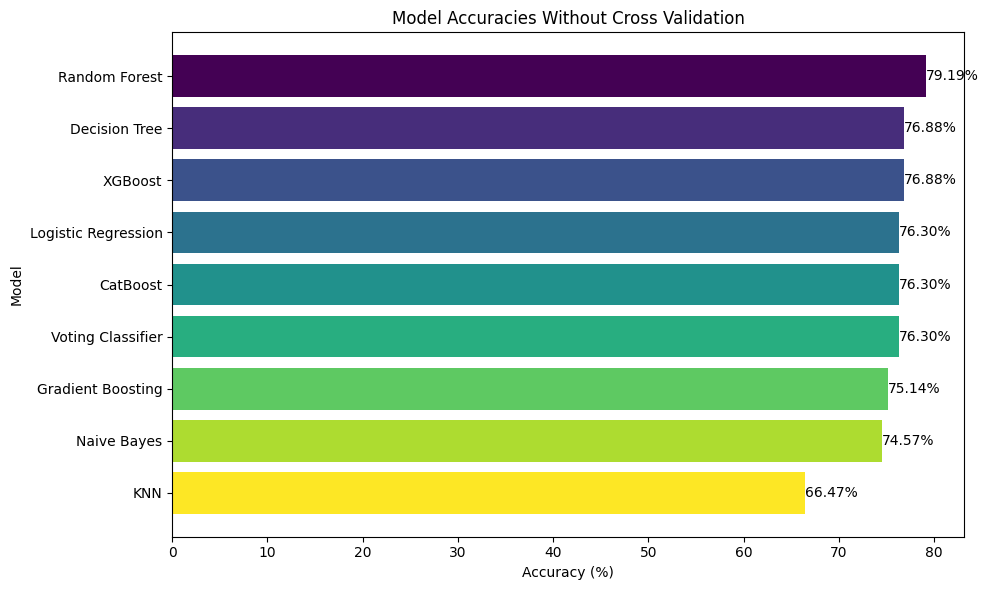

<Figure size 640x480 with 0 Axes>

In [ ]:
model_accuracies = {}
for model_name, report in classification_reports.items():
    model_accuracies[model_name] = report['accuracy'] * 100  # Convert to percentage

sorted_models = dict(sorted(model_accuracies.items(), key=lambda item: item[1], reverse=True))

plt.figure(figsize=(10, 6))
colors = plt.cm.viridis(np.linspace(0, 1, len(sorted_models)))
plt.barh(list(sorted_models.keys()), list(sorted_models.values()), color=colors)
plt.xlabel("Accuracy (%)")
plt.ylabel("Model")
plt.title("Model Accuracies Without Cross Validation")

for index, value in enumerate(sorted_models.values()):
    plt.text(value, index, f"{value:.2f}%", va='center')

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()
plt.savefig('Model Accuracy Without Cross Validation.png', bbox_inches='tight', pad_inches=0.1)

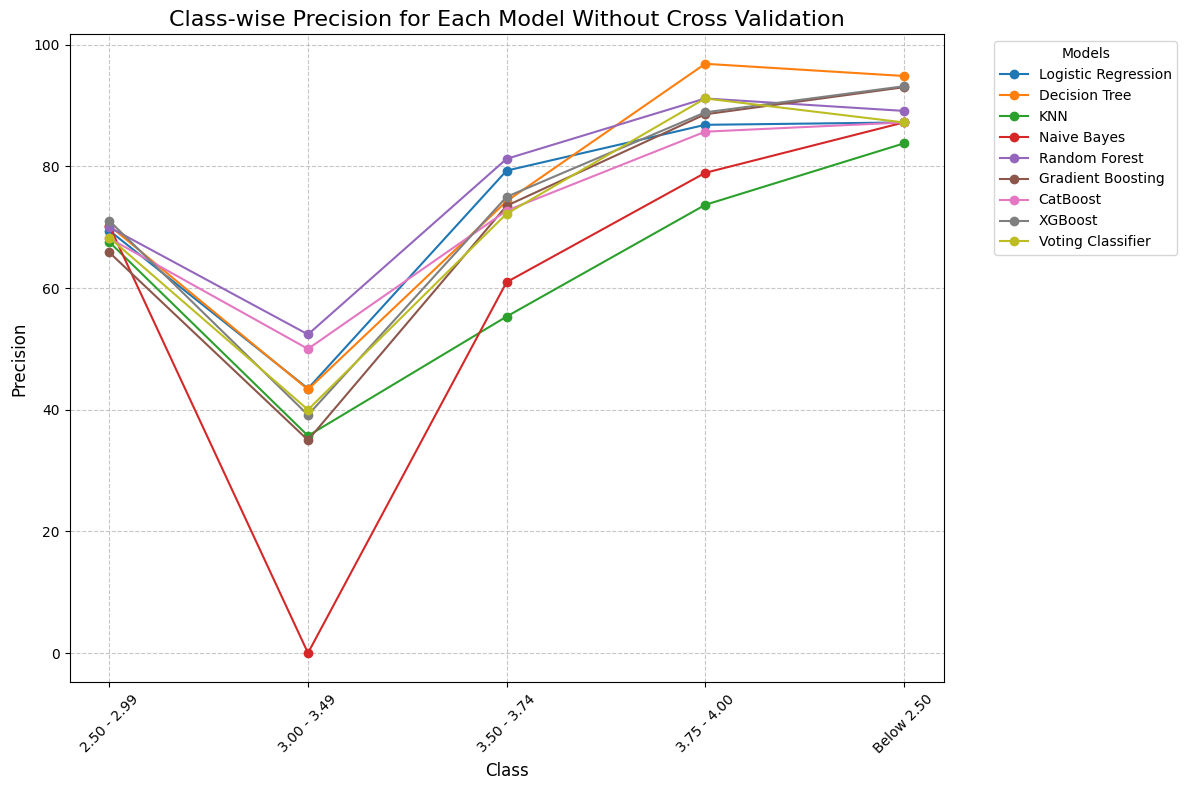

<Figure size 640x480 with 0 Axes>

In [ ]:
import matplotlib.pyplot as plt

# Define class names
class_names = {
    0: "2.50 - 2.99",
    1: "3.00 - 3.49",
    2: "3.50 - 3.74",
    3: "3.75 - 4.00",
    4: "Below 2.50",
}

# Extract class-wise precision from saved reports
model_class_accuracies = {}
for model_name, report in classification_reports.items():
    # Collect precision for each class
    model_class_accuracies[model_name] = [
        report[str(class_idx)]["precision"]*100 for class_idx in range(len(class_names))
    ]

# Convert class indices to labels for the x-axis
x_labels = [class_names[i] for i in range(len(class_names))]

# Plotting the results
plt.figure(figsize=(12, 8))

# Plot each model's class-wise accuracy
for model_name, accuracies in model_class_accuracies.items():
    plt.plot(x_labels, accuracies, marker="o", label=model_name)

# Customize the plot
plt.title("Class-wise Precision for Each Model Without Cross Validation", fontsize=16)
plt.xlabel("Class", fontsize=12)
plt.ylabel("Precision", fontsize=12)
plt.xticks(rotation=45)
plt.legend(title="Models", bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()

# Show the plot
plt.show()

plt.savefig('Model Accuracy Without Cross Validation for each class.png', bbox_inches='tight', pad_inches=0.1)

# **Model Training Using Cross Validation**

In [ ]:
from sklearn.model_selection import cross_val_score, cross_val_predict, KFold
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from catboost import CatBoostClassifier
import xgboost as xgb
import numpy as np

# Define classification models
classification_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(),
    "KNN": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(),
    #"SVM": SVC(probability=True),
    "Gradient Boosting": GradientBoostingClassifier(),
    "CatBoost": CatBoostClassifier(loss_function = 'MultiClass',cat_features=cat_features, verbose=False),
    "XGBoost": xgb.XGBClassifier(eval_metric='mlogloss')
}

classification_reports_Cross_Validation = {}
classification_model_Cress_ValidationK={}
accuracy_scores = {}
mean_accuracies = {}

# Define cross-validation strategy

kfold = KFold(n_splits=5, shuffle=True, random_state=42)

# Train and evaluate classification models using cross-validation
print("\n=== Classification Models ===")
for model_name, model in classification_models.items():
    print(f"\nTraining {model_name} with Cross-Validation...")
    # Cross-validation scores for accuracy
    cv_scores = cross_val_score(model, X, y, cv=kfold, scoring='accuracy')

    # Cross-validation predictions
    y_pred = cross_val_predict(model, X, y, cv=kfold)

    # Classification Report
    print(f"\nCross-Validation Accuracy Scores: {cv_scores}")
    print(f"Mean Accuracy: {cv_scores.mean():.4f}, Std Dev: {cv_scores.std():.4f}")
    print("\nClassification Report:")
    print(classification_report(y, y_pred, zero_division=0))

    # Save the report for further analysis
    classification_reports_Cross_Validation[model_name] = classification_report(y, y_pred, output_dict=True, zero_division=0)
    classification_model_Cress_ValidationK[model_name]=model
    accuracy_scores[model_name] = cv_scores
    mean_accuracies[model_name] = cv_scores.mean()



=== Classification Models ===

Training Logistic Regression with Cross-Validation...


/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c


Cross-Validation Accuracy Scores: [0.76300578 0.69942197 0.75722543 0.79768786 0.73988439]
Mean Accuracy: 0.7514, Std Dev: 0.0321

Classification Report:
              precision    recall  f1-score   support

           0       0.66      0.74      0.70       173
           1       0.64      0.45      0.52       173
           2       0.73      0.68      0.70       173
           3       0.79      0.90      0.84       173
           4       0.88      1.00      0.94       173

    accuracy                           0.75       865
   macro avg       0.74      0.75      0.74       865
weighted avg       0.74      0.75      0.74       865


Training Decision Tree with Cross-Validation...

Cross-Validation Accuracy Scores: [0.73410405 0.65317919 0.75144509 0.79190751 0.76300578]
Mean Accuracy: 0.7387, Std Dev: 0.0467

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.65      0.65       173
           1       0.57      0.61      0.59

In [ ]:
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import KFold, cross_val_score, cross_val_predict

# Define VotingClassifier using pre-trained models
voting_clf = VotingClassifier(
    estimators=[
        ('Logistic Regression', classification_model_Cress_ValidationK["Logistic Regression"]),
        ('Decision Tree', classification_model_Cress_ValidationK["Decision Tree"]),
        ('KNN', classification_model_Cress_ValidationK["KNN"]),
        ('Naive Bayes', classification_model_Cress_ValidationK["Naive Bayes"]),
        ('Random Forest', classification_model_Cress_ValidationK["Random Forest"]),
       # ('SVM', classification_model_Cress_ValidationK["SVM"]),
        ('Gradient Boosting', classification_model_Cress_ValidationK["Gradient Boosting"]),
        ('CatBoost', classification_model_Cress_ValidationK["CatBoost"]),
        ('XGBoost', classification_model_Cress_ValidationK["XGBoost"])
    ],
    voting='soft',  # Use probabilities for aggregation
    n_jobs=-1  # Use all available cores
)

# Initialize K-Fold
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

# Perform K-Fold Cross-Validation
print("\nPerforming K-Fold Cross-Validation for Voting Classifier...")
cv_scores = cross_val_score(voting_clf, X, y, cv=kfold, scoring='accuracy', n_jobs=-1)

# Cross-validation predictions
y_pred_kfold = cross_val_predict(voting_clf, X, y, cv=kfold)

# Evaluate the VotingClassifier with K-Fold
accuracy_kfold = cv_scores.mean()
std_dev_kfold = cv_scores.std()
print(cv_scores)
print(f"\nVoting Classifier - K-Fold Accuracy: {accuracy_kfold:.4f} ± {std_dev_kfold:.4f}")
print("\nClassification Report for Cross-Validated Predictions:")
print(classification_report(y, y_pred_kfold, zero_division=0))

# Store the trained VotingClassifier in the dictionary
classification_model_Cress_ValidationK["Voting Classifier"] = voting_clf
accuracy_scores["Voting Classifier"] = cv_scores
classification_reports_Cross_Validation["Voting Classifier"] = classification_report(y, y_pred_kfold, output_dict=True, zero_division=0)
mean_accuracies["Voting Classifier"] = accuracy_kfold

# Confirm addition to the dictionary
print("\nVoting Classifier added to classification_models dictionary.")



Performing K-Fold Cross-Validation for Voting Classifier...
[0.78034682 0.7283237  0.79190751 0.84971098 0.75722543]

Voting Classifier - K-Fold Accuracy: 0.7815 ± 0.0404

Classification Report for Cross-Validated Predictions:
              precision    recall  f1-score   support

           0       0.66      0.77      0.71       173
           1       0.65      0.43      0.52       173
           2       0.78      0.78      0.78       173
           3       0.88      0.92      0.90       173
           4       0.88      1.00      0.94       173

    accuracy                           0.78       865
   macro avg       0.77      0.78      0.77       865
weighted avg       0.77      0.78      0.77       865


Voting Classifier added to classification_models dictionary.


# **Visualising there Accuracy**

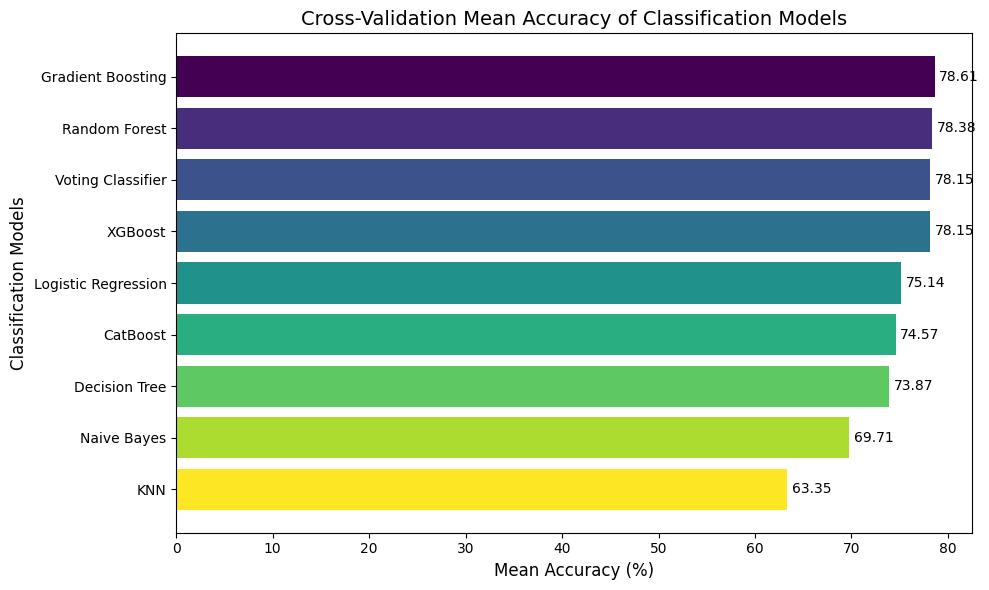

<Figure size 640x480 with 0 Axes>

In [ ]:

model_names = list(accuracy_scores.keys())
mean_accuracy = [np.mean(scores) * 100 for scores in accuracy_scores.values()]

sorted_indices = np.argsort(mean_accuracy)[::-1]
sorted_model_names = [model_names[i] for i in sorted_indices]
sorted_mean_accuracy = [mean_accuracy[i] for i in sorted_indices]

colors = plt.cm.viridis(np.linspace(0, 1, len(sorted_model_names)))

plt.figure(figsize=(10, 6))
plt.barh(sorted_model_names, sorted_mean_accuracy, color=colors)
plt.xlabel("Mean Accuracy (%)", fontsize=12)
plt.ylabel("Classification Models", fontsize=12)
plt.title("Cross-Validation Mean Accuracy of Classification Models", fontsize=14)

for i, v in enumerate(sorted_mean_accuracy):
    plt.text(v + 0.5, i, f"{v:.2f}", color='black', va='center')

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

plt.savefig('Model Accuracy With Cross Validation Mean Accuracy.png', bbox_inches='tight', pad_inches=0.1)

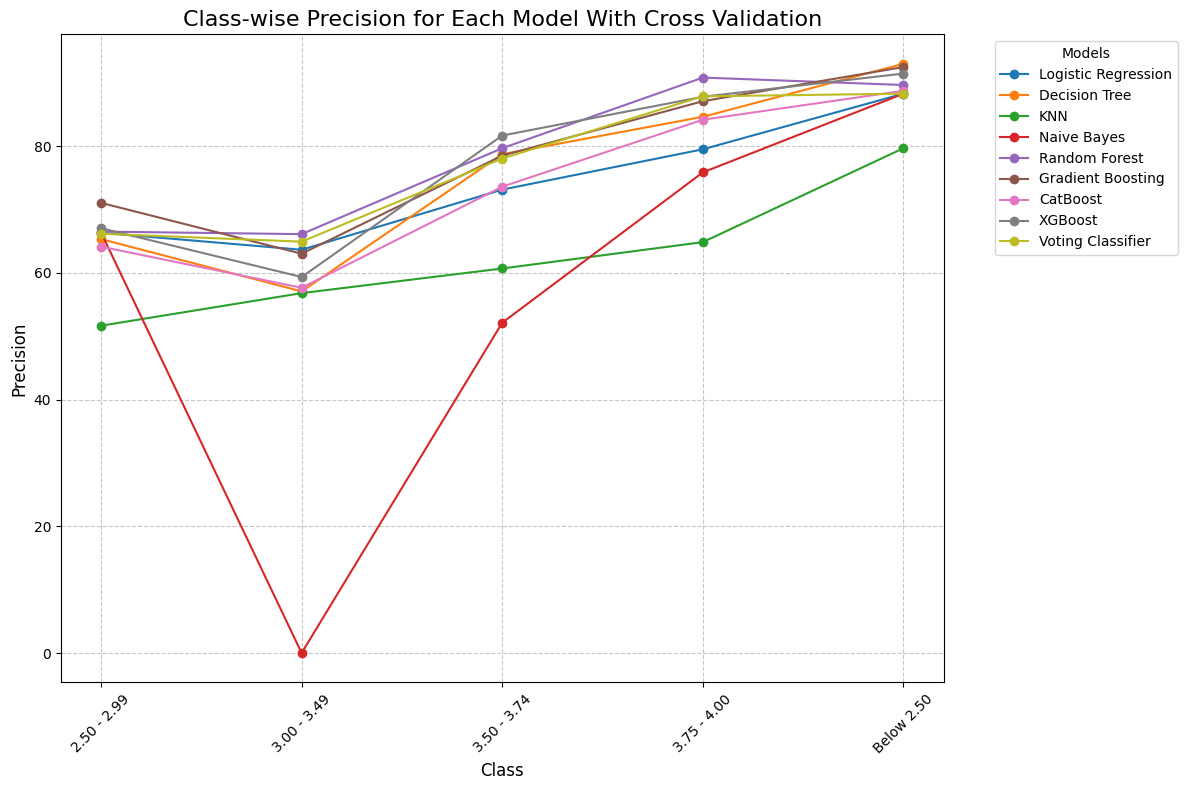

<Figure size 640x480 with 0 Axes>

In [ ]:
import matplotlib.pyplot as plt

# Define class names
class_names = {
    0: "2.50 - 2.99",
    1: "3.00 - 3.49",
    2: "3.50 - 3.74",
    3: "3.75 - 4.00",
    4: "Below 2.50",
}

# Extract class-wise precision from saved reports
model_class_accuracies = {}
for model_name, report in classification_reports_Cross_Validation.items():
    # Collect precision for each class
    model_class_accuracies[model_name] = [
        report[str(class_idx)]["precision"]*100 for class_idx in range(len(class_names))
    ]

# Convert class indices to labels for the x-axis
x_labels = [class_names[i] for i in range(len(class_names))]

# Plotting the results
plt.figure(figsize=(12, 8))

# Plot each model's class-wise accuracy
for model_name, accuracies in model_class_accuracies.items():
    plt.plot(x_labels, accuracies, marker="o", label=model_name)

# Customize the plot
plt.title("Class-wise Precision for Each Model With Cross Validation", fontsize=16)
plt.xlabel("Class", fontsize=12)
plt.ylabel("Precision", fontsize=12)
plt.xticks(rotation=45)
plt.legend(title="Models", bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()

# Show the plot
plt.show()

plt.savefig('Model Accuracy With Cross Validation class wish.png', bbox_inches='tight', pad_inches=0.1)


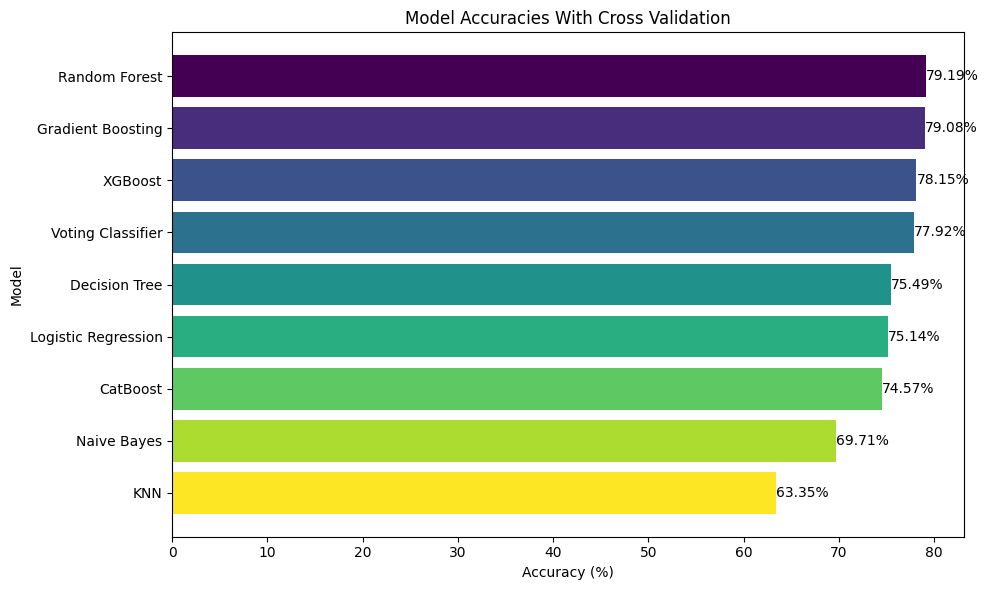

<Figure size 640x480 with 0 Axes>

In [ ]:
model_accuracies = {}

for model_name, report in classification_reports_Cross_Validation.items():
    model_accuracies[model_name] = report['accuracy'] * 100

sorted_models = dict(sorted(model_accuracies.items(), key=lambda item: item[1], reverse=True))

plt.figure(figsize=(10, 6))
colors = plt.cm.viridis(np.linspace(0, 1, len(sorted_models)))
plt.barh(list(sorted_models.keys()), list(sorted_models.values()), color=colors)
plt.xlabel("Accuracy (%)")
plt.ylabel("Model")
plt.title("Model Accuracies With Cross Validation")

for index, value in enumerate(sorted_models.values()):
    plt.text(value, index, f"{value:.2f}%", va='center')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

plt.savefig('Model Accuracy With Cross Validation.png', bbox_inches='tight', pad_inches=0.1)

# **Confusion Matrics**

Saved confusion matrix for Logistic Regression at /content/drive/MyDrive/MlLab/Model Runs Machine Learning Course/confusion_matrices_20241203-181618/Logistic_Regression_confusion_matrix.png


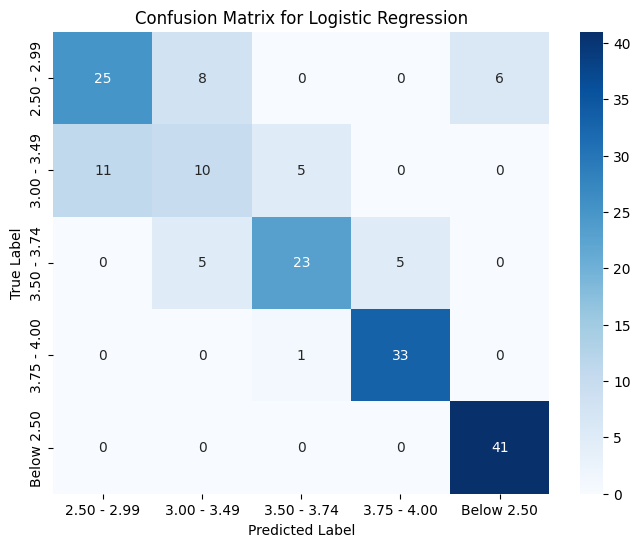

Saved confusion matrix for Decision Tree at /content/drive/MyDrive/MlLab/Model Runs Machine Learning Course/confusion_matrices_20241203-181618/Decision_Tree_confusion_matrix.png


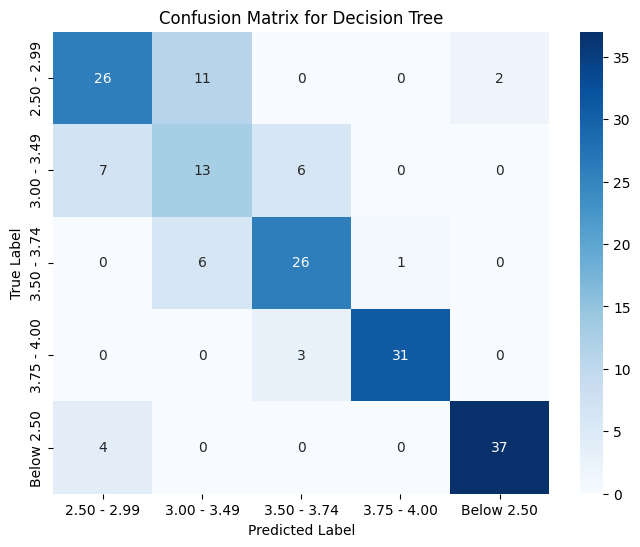

Saved confusion matrix for KNN at /content/drive/MyDrive/MlLab/Model Runs Machine Learning Course/confusion_matrices_20241203-181618/KNN_confusion_matrix.png


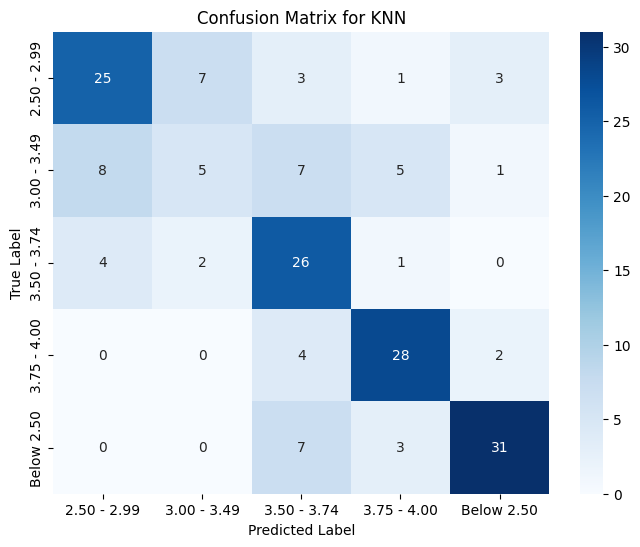

Saved confusion matrix for Naive Bayes at /content/drive/MyDrive/MlLab/Model Runs Machine Learning Course/confusion_matrices_20241203-181618/Naive_Bayes_confusion_matrix.png


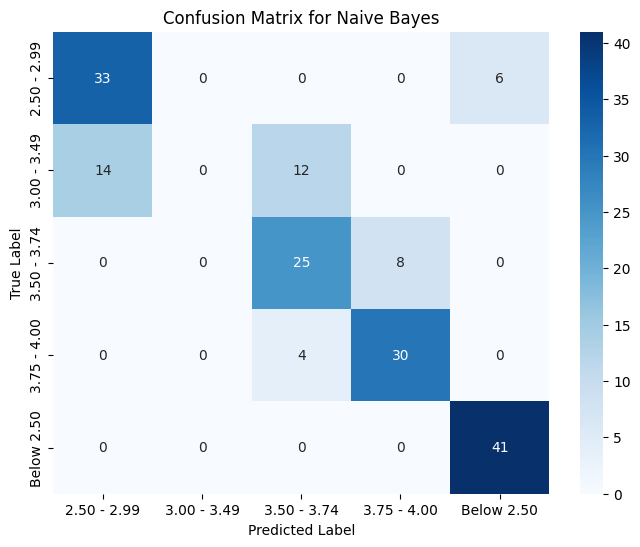

Saved confusion matrix for Random Forest at /content/drive/MyDrive/MlLab/Model Runs Machine Learning Course/confusion_matrices_20241203-181618/Random_Forest_confusion_matrix.png


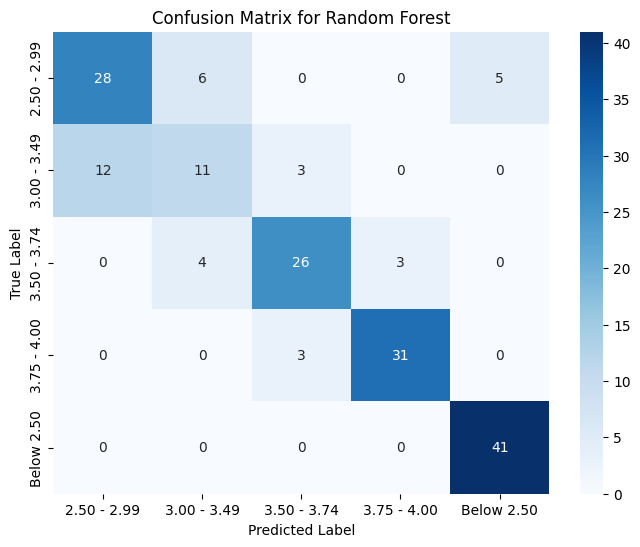

Saved confusion matrix for Gradient Boosting at /content/drive/MyDrive/MlLab/Model Runs Machine Learning Course/confusion_matrices_20241203-181618/Gradient_Boosting_confusion_matrix.png


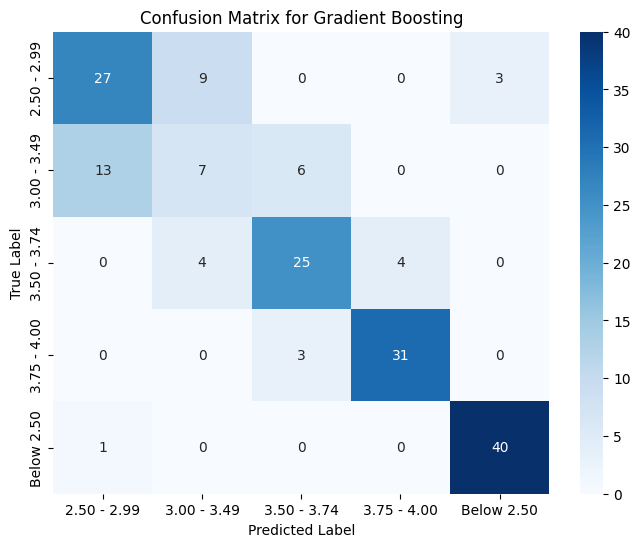

Saved confusion matrix for CatBoost at /content/drive/MyDrive/MlLab/Model Runs Machine Learning Course/confusion_matrices_20241203-181618/CatBoost_confusion_matrix.png


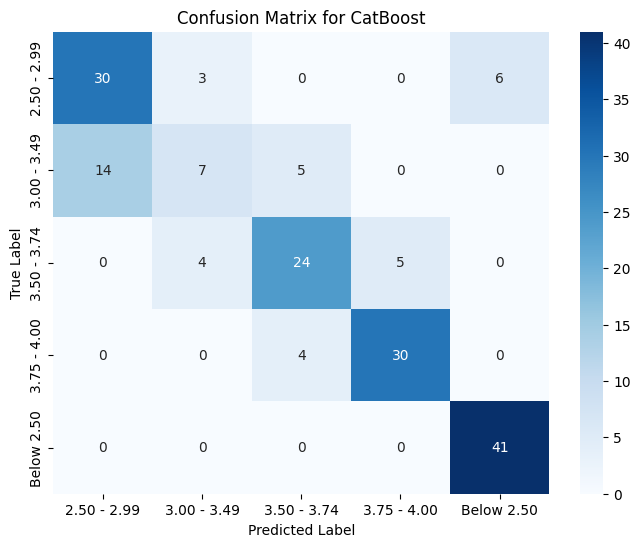

Saved confusion matrix for XGBoost at /content/drive/MyDrive/MlLab/Model Runs Machine Learning Course/confusion_matrices_20241203-181618/XGBoost_confusion_matrix.png


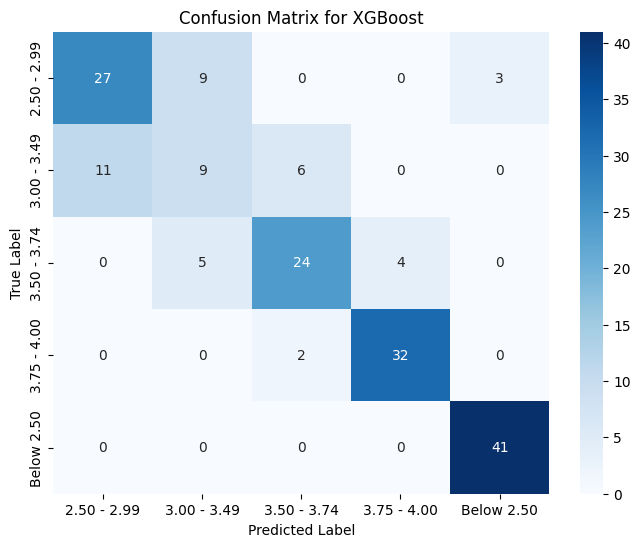

Saved confusion matrix for Voting Classifier at /content/drive/MyDrive/MlLab/Model Runs Machine Learning Course/confusion_matrices_20241203-181618/Voting_Classifier_confusion_matrix.png


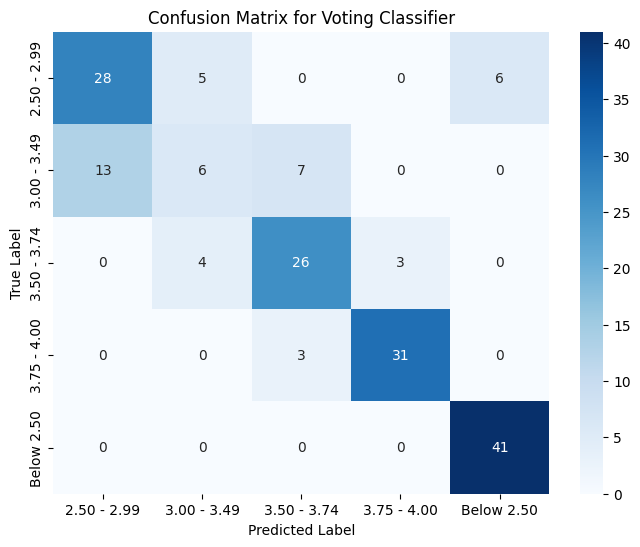

In [ ]:

timestamp = time.strftime("%Y%m%d-%H%M%S")
output_dir = f"/content/drive/MyDrive/MlLab/Model Runs Machine Learning Course/confusion_matrices_{timestamp}"
os.makedirs(output_dir)

for model_name, model in classification_model.items():
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names.values(),
                yticklabels=class_names.values())
    plt.title(f'Confusion Matrix for {model_name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')

    file_path = os.path.join(output_dir, f"{model_name.replace(' ', '_')}_confusion_matrix.png")
    plt.savefig(file_path)
    print(f"Saved confusion matrix for {model_name} at {file_path}")

    plt.show()

    plt.close()



In [ ]:
def figure_save(filename):
  import matplotlib.pyplot as plt
  fig = plt.figure()
  plt.savefig(f'{filename}.png',bbox_inches="tight")  # Save the plot to a file
  plt.show()
  plt.close()  #

In [ ]:
from graphviz import Digraph

# Create a flowchart
flow = Digraph(format="png")
flow.node("A", "Start")
flow.node("B", "Dataset Import & Preprocessing")
flow.node("C", "Data Balancing")
flow.node("D", "Feature Selection")
flow.node("E", "Train-Test Split")
flow.node("F", "Model Training")
flow.node("G", "Cross-Validation")
flow.node("H", "Model Comparison")
flow.node("I", "End")

flow.edges(["AB", "BC", "CD", "DE", "EF", "FG", "GH", "HI"])
flow.render("methodology_flowchart")


'methodology_flowchart.png'

PermutationExplainer explainer: 174it [01:24,  1.92it/s]


SHAP values shape: (173, 14)
X_test shape: (173, 14)


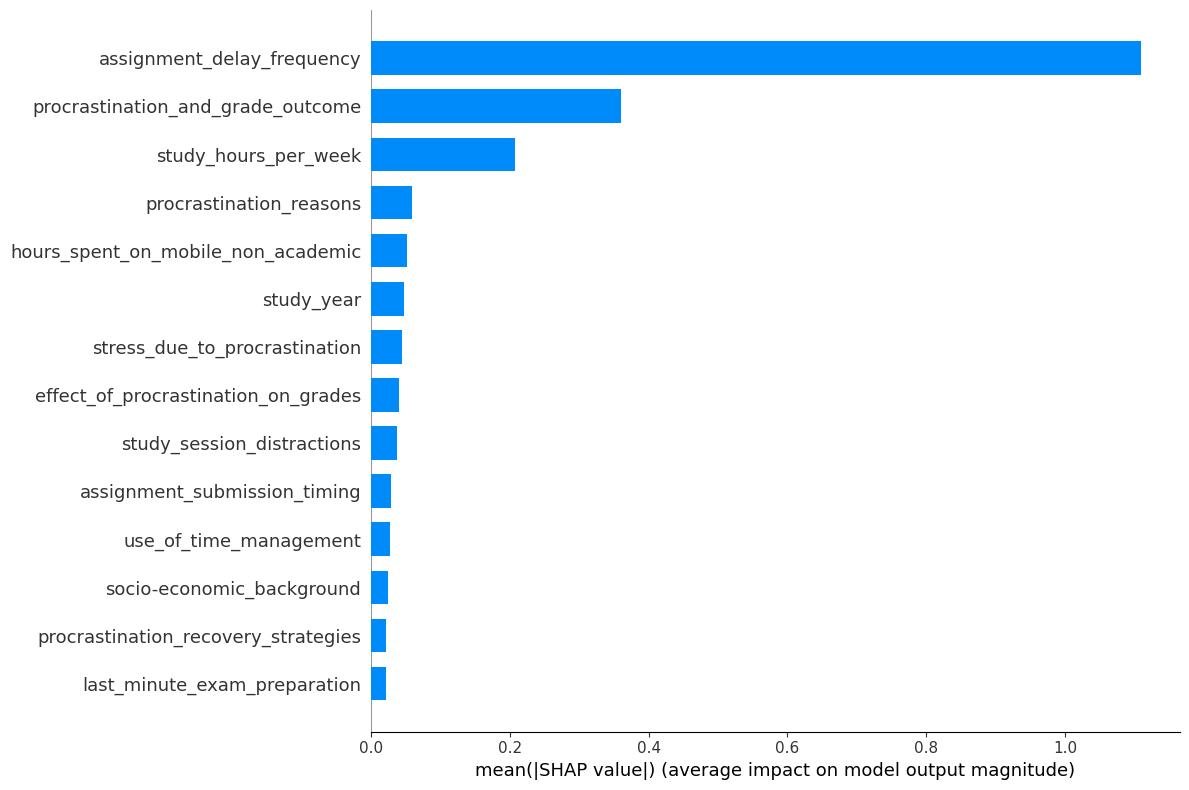

In [ ]:
import shap
import numpy as np

'''
# Create SHAP explainer
explainer = shap.Explainer(classification_model_Cress_ValidationK["Random Forest"].predict, X_test)
shap_values = explainer(X_test)
'''
# Get the Random Forest model (which might be a pipeline)
model = classification_model_Cress_ValidationK["Random Forest"]

# Fit the model on the entire training data
model.fit(X_train, y_train) # Fit on all training data

# Create SHAP explainer with the fitted model
explainer = shap.Explainer(model.predict, X_test)
shap_values = explainer(X_test)

# Check the shape of SHAP values and input data
print("SHAP values shape:", shap_values.values.shape)
print("X_test shape:", X_test.shape)

# Aggregate SHAP values for multiclass classification
if len(shap_values.values.shape) == 3:  # Multiclass case
    shap_values_combined = shap_values.values.mean(axis=2)  # Aggregate over classes
else:  # Binary classification or regression
    shap_values_combined = shap_values.values

import matplotlib.pyplot as plt
fig = plt.figure()


# Generate summary plot
#shap.summary_plot(shap_values_combined, X_test(12,8),plot_type='bar',show=False)
shap.summary_plot(shap_values_combined, X_test,show=False,plot_size=(12,8),plot_type='bar')
plt.savefig('Random forest class importance.png',bbox_inches="tight")  # Save the plot to a file
plt.show()
plt.close()

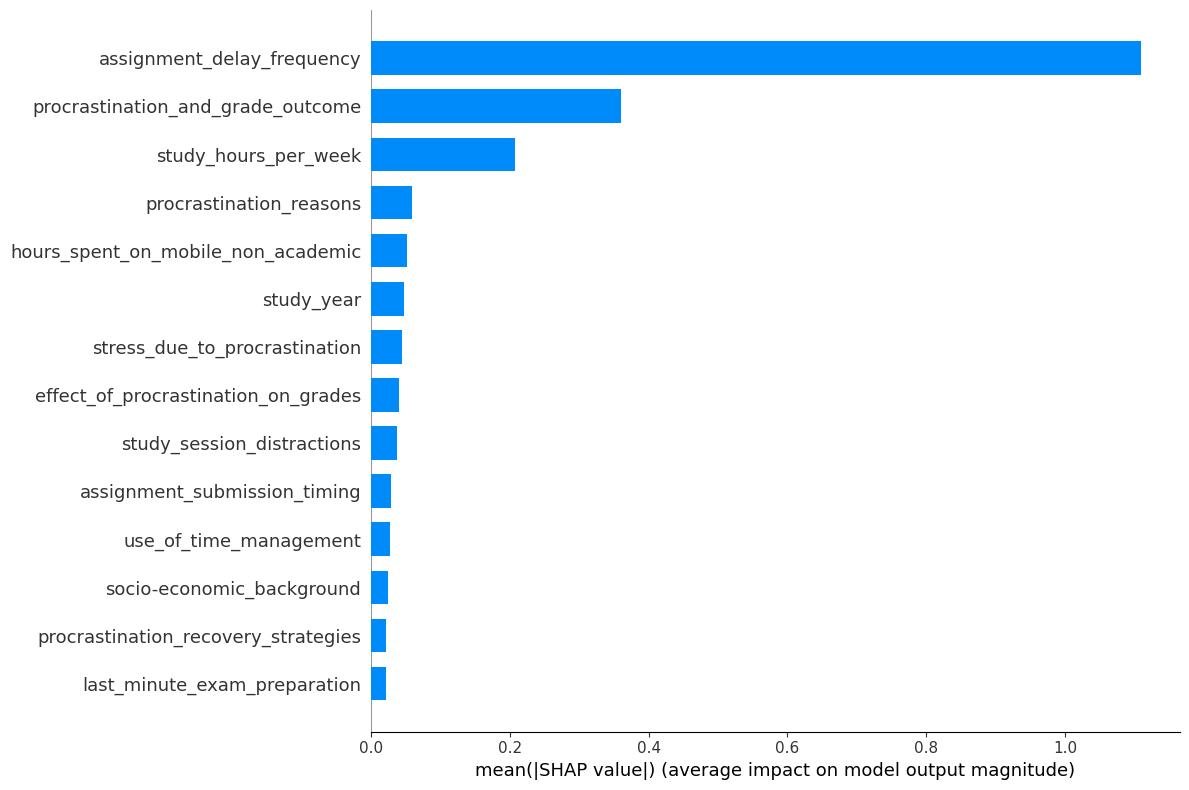

'\n#shap_values_combined = shap_values.mean(axis=2)\n\n#shap.summary_plot(shap_values_combined, X_test,plot_type=\'bar\')\nshap.summary_plot(shap_values[:,1], X,plot_type=\'bar\')\n#shap.save_html("catboost_shap_explanation.html", shap_values[:,0], X)\n'

In [ ]:
#explainer = shap.Explainer(catboost_model, X_test)
#shap_values = explainer(X_test)
'''
shap_values = classification_model_Cress_ValidationK["CatBoost"].get_feature_importance(Pool(X, y, cat_features=cat_features), type='ShapValues')

shap_values = shap_values[:,:,:-1]
'''
catboost_model = classification_model_Cress_ValidationK["CatBoost"]

# Re-train the CatBoost model on the entire training data
catboost_model.fit(X, y, cat_features=cat_features)  # Fit on all training data

# Calculate SHAP values
shap_values = catboost_model.get_feature_importance(
    Pool(X, y, cat_features=cat_features),
    type='ShapValues'
)

import matplotlib.pyplot as plt
fig = plt.figure()

shap_values_class_0 = shap_values[:, 1, :-1]

# Generate summary plot for the selected class
#shap.summary_plot(shap_values_class_0, X, plot_type='bar')
shap.summary_plot(shap_values_combined, X_test,show=False,plot_size=(12,8),plot_type='bar')
plt.savefig('Catboost Fature Importance.png',bbox_inches="tight")  # Save the plot to a file
plt.show()
plt.close()
'''
#shap_values_combined = shap_values.mean(axis=2)

#shap.summary_plot(shap_values_combined, X_test,plot_type='bar')
shap.summary_plot(shap_values[:,1], X,plot_type='bar')
#shap.save_html("catboost_shap_explanation.html", shap_values[:,0], X)
'''

PermutationExplainer explainer: 174it [01:17,  1.96it/s]


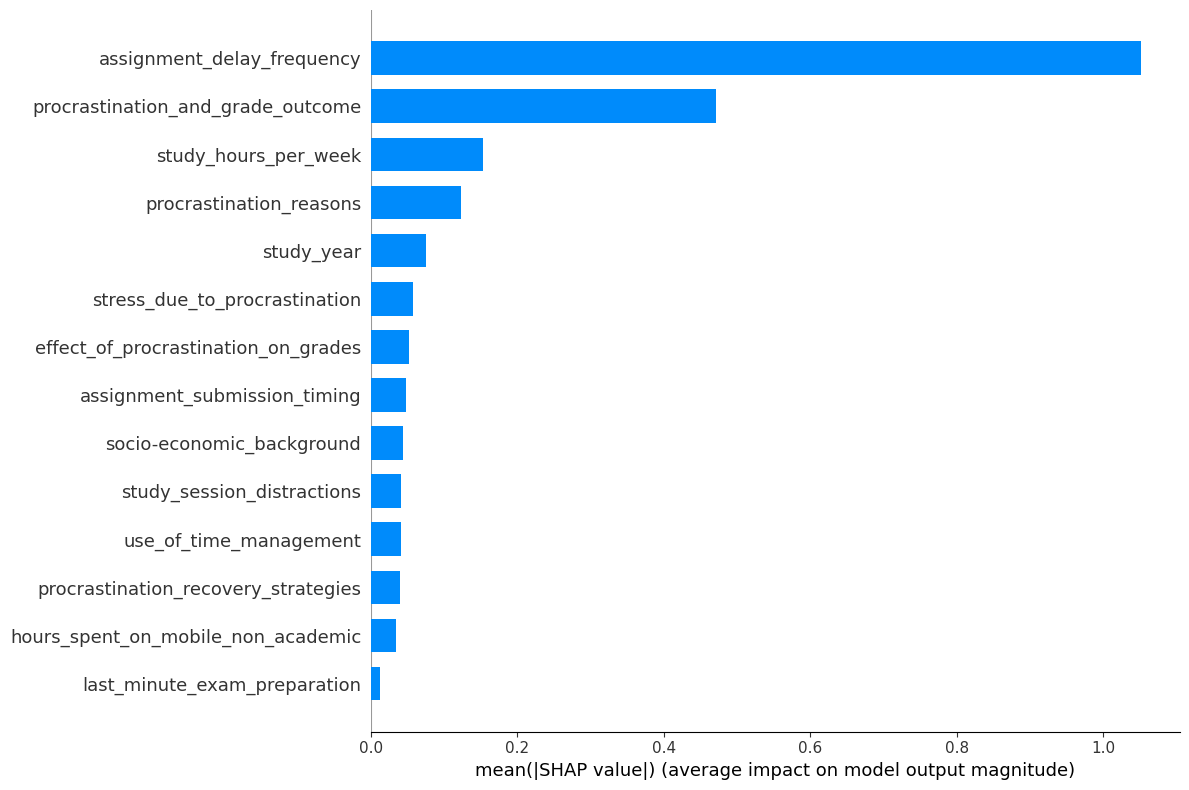

In [ ]:
model = classification_model_Cress_ValidationK["XGBoost"]

# Fit the model on the entire training data
model.fit(X_train, y_train)  # Fit on all training data

# Create SHAP explainer with the fitted model
explainer = shap.Explainer(model.predict, X_test)
shap_values = explainer(X_test)

'''
shap_values_combined = np.abs(shap_values.values).mean(axis=2)
'''
import matplotlib.pyplot as plt
fig = plt.figure()

# Check the shape of SHAP values and handle accordingly
if len(shap_values.values.shape) == 3:  # Multiclass case
    shap_values_combined = np.abs(shap_values.values).mean(axis=2)  # Aggregate over classes
elif len(shap_values.values.shape) == 2:  # Binary classification or regression
    shap_values_combined = np.abs(shap_values.values)  # Take the absolute values directly
else:
    raise ValueError("Unexpected shape of SHAP values: {}".format(shap_values.values.shape))

#plt.figure(figsize=(12,8))
#plt.tight_layout()
shap.summary_plot(shap_values_combined, X_test,show=False,plot_size=(12,8),plot_type='bar')

plt.savefig('XgBosst Feature importance.png',bbox_inches="tight")  # Save the plot to a file
plt.show()
plt.close()

In [ ]:
def figure_save(filename):
  import matplotlib.pyplot as plt
  fig = plt.figure()
  plt.savefig(f'{filename}.png',bbox_inches="tight")  # Save the plot to a file
  plt.show()
  plt.close()  #


In [ ]:
explainer = shap.KernelExplainer(classification_model["Voting Classifier"].predict, X_train, keep_index=True)
shap_values = explainer(X_test)
shap_values_combined = np.abs(shap_values.values).mean(axis=2)
shap.summary_plot(shap_values_combined, X_test,plot_type='bar')


  0%|          | 0/173 [00:00<?, ?it/s]